# Life expectancy at birth - World Bank data analysis

### import necessary libraries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
import warnings
warnings.filterwarnings("ignore")

### reading and preprocessing data

In [2]:
folder_path="../data/"

In [3]:
files={'le_total':'API_SP.DYN.LE00.IN_DS2_en_csv_v2_70864.csv',
       'le_male':'API_SP.DYN.LE00.MA.IN_DS2_en_csv_v2_74393.csv',
       'le_female':'API_SP.DYN.LE00.FE.IN_DS2_en_csv_v2_76224.csv',
       'death_rate':'API_SP.DYN.CDRT.IN_DS2_en_csv_v2_69128.csv',
       'fertility_rate':'API_SP.DYN.TFRT.IN_DS2_en_csv_v2_61105.csv'}

meta_file='Metadata_Country_API_SP.DYN.LE00.IN_DS2_en_csv_v2_70864.csv'

In [4]:
def read_files_and_combine(file_name, value_name):
    folder_name=file_name.replace('.csv', '')
    df=pd.read_csv(f"{folder_path}{folder_name}/{file_name}", skiprows=4)
    year_cols=[col for col in df.columns if col.isdigit()]
    df_long=df.melt(id_vars=['Country Name', 'Country Code'], value_vars=year_cols,
                    var_name='year', value_name=value_name)
    df_long['year']=df_long['year'].astype(int)
    return df_long

In [5]:
df=read_files_and_combine(files['le_total'], 'le_total')
for name in ['le_male', 'le_female', 'death_rate', 'fertility_rate']:
    temp=read_files_and_combine(files[name], name)
    df=df.merge(temp, on=['Country Name', 'Country Code', 'year'], how='outer')

df.shape

(17556, 8)

In [6]:
meta=pd.read_csv(f"{folder_path}{meta_file}")
meta=meta[['Country Code', 'Region', 'IncomeGroup']]
meta.head()

,Country Code,Region,IncomeGroup
0,ABW,Latin America & Caribbean,High income
1,AFE,NaN,NaN
2,AFG,Middle East & North Africa,Low income
3,AFW,NaN,NaN
4,AGO,Sub-Saharan Africa,Lower middle income


In [7]:
meta['IncomeGroup'].value_counts(dropna=False)

High income            86
Upper middle income    59
NaN                    48
Lower middle income    47
Low income             25
Name: IncomeGroup, dtype: int64

### 
48 rows have no region and no income group. These are aggregates like World, Euro area or High income and not countries, so they are removed

In [8]:
df=df.merge(meta, on='Country Code', how='left')

# remove aggregates (they dont have a region)
df=df[df['Region'].notna()]

# assignment asks for 1960 - 2023
df=df[(df['year']>=1960) & (df['year']<=2023)].reset_index(drop=True)

print(f"number of countries: {df['Country Code'].nunique()}")
print(f"number of years: {df['year'].nunique()}")
df.shape

number of countries: 217
number of years: 64


(13888, 10)

In [9]:
df.drop_duplicates(inplace=True)
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Country Name       0
Country Code       0
year               0
le_total          34
le_male           34
le_female         34
death_rate        30
fertility_rate    32
Region             0
IncomeGroup        0
dtype: int64


In [10]:
# check which country has null values
df[df.isnull().any(axis=1)].groupby('Country Name')['year'].agg(['min', 'max', 'count'])

,min,max,count
Country Name,,,
Israel,1960,1965,4
Luxembourg,1961,1963,2
West Bank and Gaza,1960,1989,30


### 
Very few missing values (less than 0.3%) and only in 3 countries: West Bank and Gaza has no data before 1990, Israel is missing 4 years between 1960 and 1965 and Luxembourg fertility is missing for 1961 and 1963

In [11]:
# fill the null only in between years for each country, no filling at the start
# ffill copies the previous year's value of the same country
cols=['le_total', 'le_male', 'le_female', 'death_rate', 'fertility_rate']
for col in cols:
    df[col]=df.groupby('Country Code')[col].ffill()

df.isnull().sum()

Country Name       0
Country Code       0
year               0
le_total          31
le_male           31
le_female         31
death_rate        30
fertility_rate    30
Region             0
IncomeGroup        0
dtype: int64

### 
The gaps in between years (Israel 1963-1965 and Luxembourg) are filled with the previous year's value of the same country. West Bank and Gaza before 1990 and Israel 1960 stay empty because there is no earlier value to copy. bfill is not used because it would give West Bank and Gaza its 1990 value for all 30 years before it

In [12]:
df.dtypes

Country Name       object
Country Code       object
year                int64
le_total          float64
le_male           float64
le_female         float64
death_rate        float64
fertility_rate    float64
Region             object
IncomeGroup        object
dtype: object

In [13]:
df[cols].describe()

,le_total,le_male,le_female,death_rate,fertility_rate
count,13857.000000,13857.000000,13857.000000,13858.000000,13858.000000
mean,65.227436,62.734352,67.860056,10.258600,3.810000
std,11.241277,10.893764,11.691467,5.675562,1.991115
min,10.989000,10.128000,11.274000,0.841000,0.586000
25%,58.432000,56.315000,60.734000,6.721250,2.020000
50%,67.900000,64.915000,70.870000,8.920000,3.234500
75%,73.394366,70.451000,76.596000,12.106500,5.681000
max,86.372000,84.448000,88.504000,153.963000,8.864000


### data quality checks

In [14]:
# total life expectancy should be between male and female life expectancy
check=df[(df['le_total']>df[['le_male', 'le_female']].max(axis=1)+0.01) |
         (df['le_total']<df[['le_male', 'le_female']].min(axis=1)-0.01)]
print(f"rows where total is not between male and female: {len(check)}")
check[['Country Name', 'year', 'le_total', 'le_male', 'le_female']].head()

rows where total is not between male and female: 12


,Country Name,year,le_total,le_male,le_female
1014,Nepal,1964,40.229,40.202,40.175
2099,Nepal,1969,42.722,42.710,42.655
2750,Nepal,1972,44.068,44.028,44.032
2967,Nepal,1973,44.485,44.449,44.446
3618,Nepal,1976,45.991,45.956,45.953


### 
12 rows (Nepal and Niger) have total life expectancy slightly outside the male - female range. The difference is very small (less than 0.1 year) so these rows are kept

In [15]:
# usually women live longer than men, checking where it is not the case
check=df[df['le_female']<df['le_male']]
print(f"rows where female life expectancy is less than male: {len(check)}")
check.groupby('Country Name')['year'].agg(['min', 'max', 'count']).sort_values('count', ascending=False)

rows where female life expectancy is less than male: 99


,min,max,count
Country Name,,,
Bangladesh,1960,1994,34
India,1960,1981,22
Pakistan,1960,1975,15
Nepal,1964,1984,14
"Iran, Islamic Rep.",1960,1970,11
Niger,1986,1986,1
North Macedonia,1960,1960,1
Zimbabwe,2007,2007,1


### 
In 99 rows women had lower life expectancy than men, mostly in South Asia in the past

In [16]:
# lowest values in the data
df.nsmallest(5, 'le_total')[['Country Name', 'year', 'le_total', 'death_rate']]

,Country Name,year,le_total,death_rate
6253,South Sudan,1988,10.989,77.739
3791,Cambodia,1977,11.295,92.984
4008,Cambodia,1978,11.573,93.923
3574,Cambodia,1976,11.632,90.595
7544,Rwanda,1994,12.158,153.963


### 
The lowest values are real events and not data errors: South Sudan 1988, Cambodia 1976-1978 and Rwanda 1994 These rows are kept and flagged with the le_drop feature

### feature engineering

In [17]:
def add_features(df):
    df=df.sort_values(['Country Code', 'year']).reset_index(drop=True)

    # how many years women live longer than men
    df['gender_gap']=df['le_female']-df['le_male']

    # change in life expectancy from last year
    df['le_total_change_1']=df.groupby('Country Code')['le_total'].diff(1)
    # average yearly change over the last 5 and 10 years (speed of improvement)
    df['le_total_change_5']=df.groupby('Country Code')['le_total'].diff(5)/5
    df['le_total_change_10']=df.groupby('Country Code')['le_total'].diff(10)/10
    df['fertility_rate_change_5']=df.groupby('Country Code')['fertility_rate'].diff(5)/5
    df['fertility_rate_change_10']=df.groupby('Country Code')['fertility_rate'].diff(10)/10
    df['death_rate_change_5']=df.groupby('Country Code')['death_rate'].diff(5)/5
    df['death_rate_change_10']=df.groupby('Country Code')['death_rate'].diff(10)/10

    # volatility: std of the yearly changes in the last 10 years (high = unstable, wars / epidemics)
    df['le_total_volatility_10']=df.groupby('Country Code')['le_total_change_1'].rolling(10).std().reset_index(level=0, drop=True)

    # 1 if life expectancy dropped more than 1 year in a single year
    df['le_drop']=(df['le_total_change_1']<-1).astype(int)
    # how far the country is from the best country in that year
    df['gap_to_best']=df.groupby('year')['le_total'].transform('max')-df['le_total']
    # difference from the average of its income group in that year
    df['diff_from_income_avg']=df['le_total']-df.groupby(['year', 'IncomeGroup'])['le_total'].transform('mean')

    return df


df=add_features(df)
df.shape

(13888, 22)

### 
Features created for each country:
- gender_gap: female - male life expectancy, used for Q1 and the model
- change features: change from last year and the average yearly change over 5 and 10 years for life expectancy, fertility and death rate. They show how fast a country is improving
- volatility: how much the yearly change jumps around in the last 10 years. It is high for countries with wars or epidemics
- le_drop: 1 when life expectancy fell by more than 1 year in a single year (wars, epidemics, covid)
- gap_to_best: how many years the country is behind the best country in that year. Countries far behind usually catch up faster
- diff_from_income_avg: how much better or worse the country is than the average of its income group

### 1. statistical analysis

In [18]:
# taking 1960 and 2023 data and keeping only countries which have data in both years
df_q=df[df['year'].isin([1960, 2023])].dropna(subset=['le_total', 'le_male', 'le_female'])
count=df_q.groupby('Country Code')['year'].count()
both_years=count[count==2].index
df_q=df_q[df_q['Country Code'].isin(both_years)]
print(f"countries with data in both years: {len(both_years)}")
df_q[df_q['year']==1960]['IncomeGroup'].value_counts()

countries with data in both years: 215


High income            85
Upper middle income    59
Lower middle income    46
Low income             25
Name: IncomeGroup, dtype: int64

### 
Only the 215 countries with data in both 1960 and 2023 are used. Income group is the current world bank classification, and the average of a group is the simple mean of its countries

#### Q1. For which income group has the difference in average life expectancy of men and women changed the most between 1960 and 2023?

In [19]:
# average gender gap (female - male) of each income group in 1960 and 2023
comparison=df_q.groupby(['IncomeGroup', 'year'])['gender_gap'].mean().unstack('year')
comparison['Economies']=df_q.groupby('IncomeGroup')['Country Code'].nunique()
comparison['Change']=comparison[2023]-comparison[1960]
comparison['Absolute change']=comparison['Change'].abs()
comparison=comparison.sort_values('Absolute change', ascending=False)
comparison

year,1960,2023,Economies,Change,Absolute change
IncomeGroup,,,,,
Upper middle income,4.262407,5.928627,59,1.666220,1.666220
Low income,2.839840,4.399200,25,1.559360,1.559360
Lower middle income,3.196609,4.586022,46,1.389413,1.389413
High income,5.239274,5.192611,85,-0.046663,0.046663


In [20]:
print(f"income group where the gender gap changed the most: {comparison.index[0]} ({round(comparison['Change'].iloc[0], 2)} years)")

income group where the gender gap changed the most: Upper middle income (1.67 years)


### 
**Upper middle income** changed the most: the gap went from 4.26 to 5.93 years (+1.67). Low income and lower middle income are very close, so the gap widened in all three non high income groups. In high income countries the gap did not change much

#### Q2. For which income group has variability in life expectancy at birth changed the most between 1960 and 2023?

In [21]:
variability=df_q.groupby(['IncomeGroup', 'year'])['le_total'].std().unstack('year')
variability['Economies']=df_q.groupby('IncomeGroup')['Country Code'].nunique()
variability['Change']=variability[2023]-variability[1960]
variability['Absolute change']=variability['Change'].abs()
variability=variability.sort_values('Absolute change', ascending=False)
variability

year,1960,2023,Economies,Change,Absolute change
IncomeGroup,,,,,
Upper middle income,7.549349,3.778299,59,-3.771050,3.771050
High income,6.909806,4.185355,85,-2.724451,2.724451
Low income,6.761530,4.600719,25,-2.160811,2.160811
Lower middle income,6.336418,4.933117,46,-1.403301,1.403301


In [22]:
print(f"income group where the variability changed the most: {variability.index[0]} ({round(variability['Change'].iloc[0], 2)} years)")

income group where the variability changed the most: Upper middle income (-3.77 years)


### 
**Upper middle income** changed the most: the standard deviation between its countries halved. Variability went down in all 4 groups  so countries inside each group became more similar over time

#### Q3. Which countries have the highest correlation between fertility rate and life expectancy at birth over the years (either positive or negative)? Which countries have the lowest correlation?

In [23]:
corr_list=[]
for country in df['Country Name'].unique():
    temp=df[df['Country Name']==country].dropna(subset=['fertility_rate', 'le_total'])
    corr=temp['fertility_rate'].corr(temp['le_total'])
    corr_list.append({'country': country,
                      'income_group': temp['IncomeGroup'].iloc[0],
                      'years': len(temp),
                      'correlation': corr})

df_corr=pd.DataFrame(corr_list)
df_corr['abs_correlation']=df_corr['correlation'].abs()
df_corr=df_corr.sort_values('abs_correlation', ascending=False).reset_index(drop=True)
df_corr.shape

(217, 5)

In [24]:
print("Strongest by magnitude")
display(df_corr.nlargest(3, "abs_correlation").round(4))
print("Highest positive")
display(df_corr.nlargest(3, "correlation").round(4))
print("Weakest by magnitude")
display(df_corr.nsmallest(3, "abs_correlation").round(4))

Strongest by magnitude


,country,income_group,years,correlation,abs_correlation
0,India,Lower middle income,64,-0.9973,0.9973
1,Brunei Darussalam,High income,64,-0.9943,0.9943
2,Ghana,Lower middle income,64,-0.9937,0.9937


Highest positive


,country,income_group,years,correlation,abs_correlation
204,Zimbabwe,Lower middle income,64,0.3452,0.3452
206,Lesotho,Lower middle income,64,0.3159,0.3159
209,Russian Federation,High income,64,0.1991,0.1991


Weakest by magnitude


,country,income_group,years,correlation,abs_correlation
216,Belarus,Upper middle income,64,0.0204,0.0204
215,Eswatini,Lower middle income,64,0.0400,0.0400
214,Central African Republic,Low income,64,0.0866,0.0866


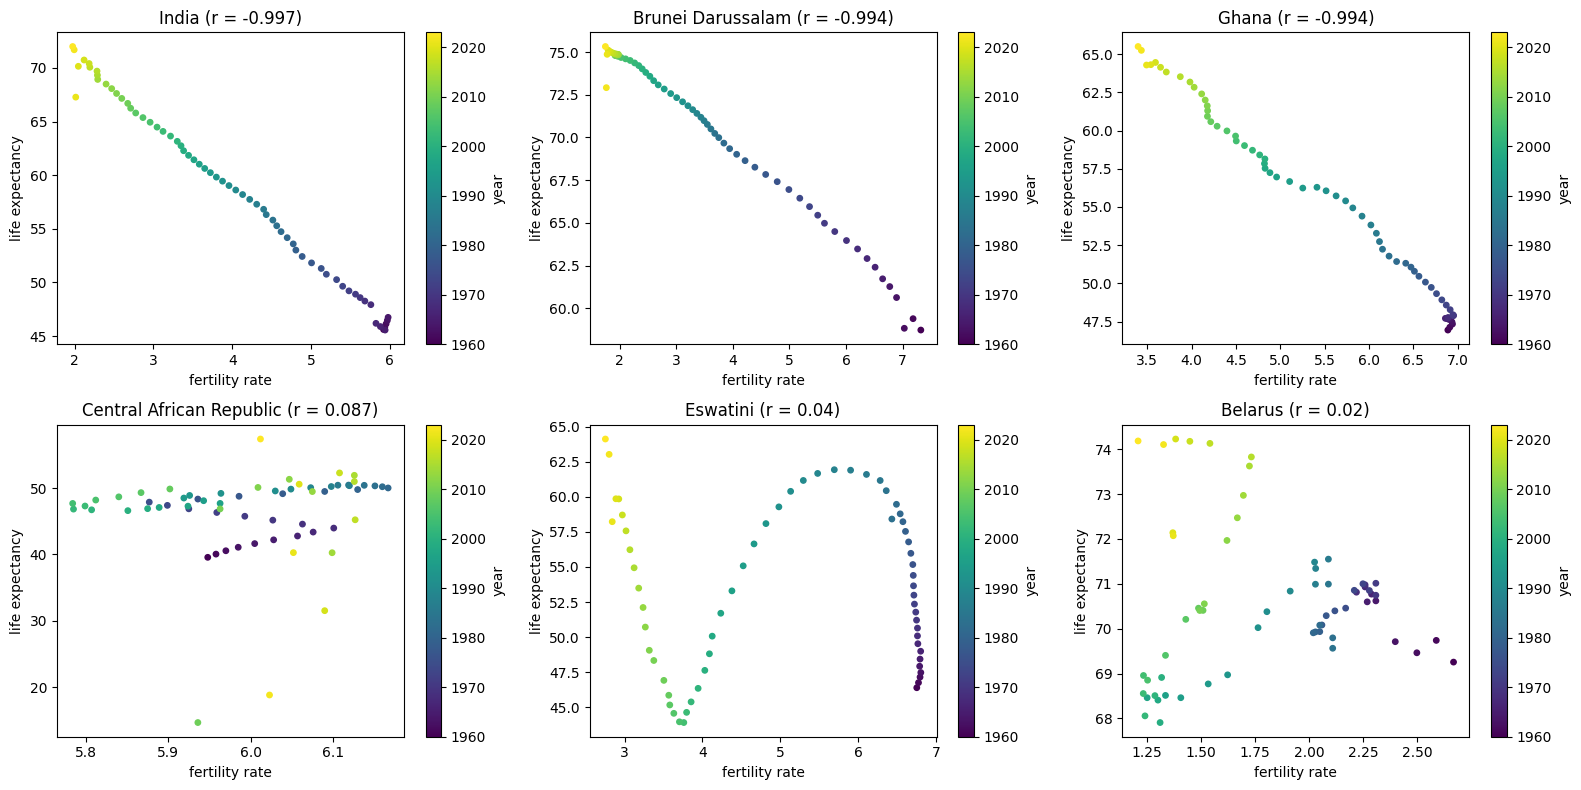

In [25]:
countries=list(df_corr['country'].head(3))+list(df_corr['country'].tail(3))
plt.figure(figsize=(16, 8))
for i, country in enumerate(countries, 1):
    plt.subplot(2, 3, i)
    temp=df[df['Country Name']==country]
    plt.scatter(temp['fertility_rate'], temp['le_total'], c=temp['year'], cmap='viridis', s=15)
    r=df_corr[df_corr['country']==country]['correlation'].values[0]
    plt.title(f'{country} (r = {round(r, 3)})')
    plt.xlabel('fertility rate')
    plt.ylabel('life expectancy')
    plt.colorbar(label='year')
plt.tight_layout()
plt.show()

### 
**Highest correlation:** India, Brunei and Ghana. All the strongest correlations are negative. In the plots these countries are almost a straight line: every year fertility went down a little and life expectancy went up a little.

**Lowest correlation:** Belarus, Eswatini and Central African Republic. The plots show why:

The most positive correlations are Zimbabwe, Lesotho  and Russia , where life expectancy fell (eg HIV/AIDS) at the same time as fertility. Correlation shows that the two move together over time, not that one causes the other

### 2. data visualizations

#### life expectancy over time by income group

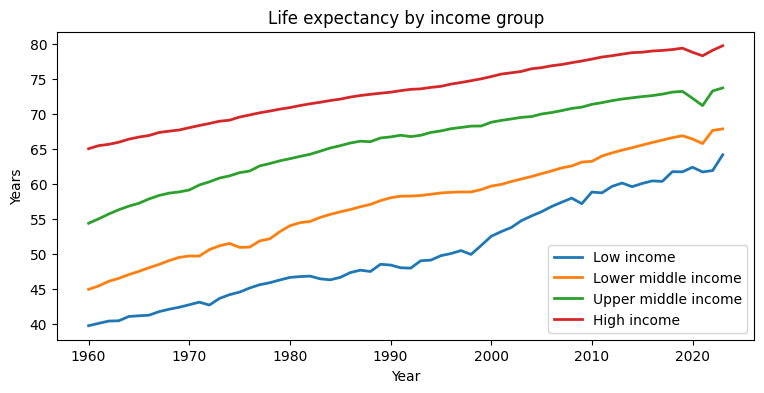

year
1960    25.3
2023    15.6
Name: High - low income gap in years, dtype: float64

In [26]:
income_order=['Low income', 'Lower middle income', 'Upper middle income', 'High income']
income_trend=df.pivot_table(index='year', columns='IncomeGroup', values='le_total', aggfunc='mean')
ax=income_trend[income_order].plot(figsize=(9, 4), linewidth=2)
ax.set(title='Life expectancy by income group', ylabel='Years', xlabel='Year')
ax.legend(title=None)
plt.show()

high_low_gap=income_trend['High income']-income_trend['Low income']
high_low_gap.loc[[1960, 2023]].round(1).rename('High - low income gap in years')

### 
Life expectancy increased in all 4 income groups and the order never changed: high income is always on top and low income at the bottom. Low income countries improved the most, so the gap between high and low income came down. The low income line is less smooth (wars, HIV/AIDS and all groups dip in 2020-2021 because of covid, with upper middle income falling the most

#### world map of life expectancy in 2023

In [ ]:
df_2023=df[df['year']==2023]
fig=px.choropleth(df_2023, locations='Country Code', color='le_total', hover_name='Country Name',
                  hover_data=['IncomeGroup', 'Region'], color_continuous_scale='RdYlGn',
                  labels={'le_total': 'Life expectancy'},
                  title='Life expectancy at birth in 2023')
fig.update_layout(geo=dict(showframe=False, projection_type='natural earth'), height=550,
                  margin=dict(l=0, r=0, t=50, b=0))
fig.show()
fig.write_html("world_map_2023.html")

### 
Sub-Saharan Africa is clearly the lowest region: all 6 countries below 60 years are there. The highest values are in Western Europe, Japan, Korea, Australia, Canada and Monaco

#### sankey diagram: life expectancy bucket in 1960 vs 2023
For 1960 and 2023, rank the countries by life expectancy and divide them into 5 buckets of equal size, then show how countries moved between the buckets

In [28]:
labels=['Very low life expectancy', 'Low life expectancy', 'Medium life expectancy',
        'High life expectancy', 'Very high life expectancy']

sankey_df=df[df['year']==1960][['Country Name', 'le_total']].merge(
    df[df['year']==2023][['Country Name', 'le_total']], on='Country Name', suffixes=('_1960', '_2023')).dropna()

sankey_df['bucket_1960']=pd.qcut(sankey_df['le_total_1960'].rank(method='first'), 5, labels=labels)
sankey_df['bucket_2023']=pd.qcut(sankey_df['le_total_2023'].rank(method='first'), 5, labels=labels)

print(sankey_df['bucket_1960'].value_counts())
print(sankey_df['bucket_2023'].value_counts())

Very low life expectancy     43
Low life expectancy          43
Medium life expectancy       43
High life expectancy         43
Very high life expectancy    43
Name: bucket_1960, dtype: int64
Very low life expectancy     43
Low life expectancy          43
Medium life expectancy       43
High life expectancy         43
Very high life expectancy    43
Name: bucket_2023, dtype: int64


In [29]:
sankey_df

,Country Name,le_total_1960,le_total_2023,bucket_1960,bucket_2023
0,Aruba,64.049,76.353,High life expectancy,Medium life expectancy
1,Afghanistan,32.799,66.035,Very low life expectancy,Very low life expectancy
2,Angola,37.933,64.617,Very low life expectancy,Very low life expectancy
3,Albania,56.413,79.602,Medium life expectancy,High life expectancy
4,Andorra,72.094,84.041,Very high life expectancy,Very high life expectancy
...,...,...,...,...,...
212,Kosovo,48.702,78.033,Low life expectancy,High life expectancy
213,"Yemen, Rep.",33.462,69.295,Very low life expectancy,Low life expectancy
214,South Africa,52.575,66.139,Medium life expectancy,Very low life expectancy
215,Zambia,50.648,66.349,Low life expectancy,Very low life expectancy


In [30]:
# bucket number: very low = 0 ... very high = 4, so moving up means the 2023 number is bigger
tier_number={l: n for n, l in enumerate(labels)}
sankey_df['movement']=sankey_df['bucket_2023'].map(tier_number).astype(int)-sankey_df['bucket_1960'].map(tier_number).astype(int)
print(f"{(sankey_df['movement']>0).sum()} moved up, {(sankey_df['movement']<0).sum()} moved down, "
      f"{(sankey_df['movement']==0).sum()} stayed in the same group")

52 moved up, 62 moved down, 101 stayed in the same group


In [31]:
# countries which moved 2 or more buckets
sankey_df[sankey_df['movement'].abs()>=2].sort_values('movement', ascending=False)[['Country Name', 'bucket_1960', 'bucket_2023', 'movement']]

,Country Name,bucket_1960,bucket_2023,movement
5,United Arab Emirates,Low life expectancy,Very high life expectancy,3
36,China,Very low life expectancy,High life expectancy,3
124,Maldives,Very low life expectancy,High life expectancy,3
91,"Iran, Islamic Rep.",Very low life expectancy,High life expectancy,3
19,Bahrain,Low life expectancy,Very high life expectancy,3
149,Oman,Very low life expectancy,High life expectancy,3
29,Bhutan,Very low life expectancy,Medium life expectancy,2
35,Chile,Medium life expectancy,Very high life expectancy,2
212,Kosovo,Low life expectancy,High life expectancy,2
55,Algeria,Very low life expectancy,Medium life expectancy,2


In [32]:
flows=sankey_df.groupby(['bucket_1960', 'bucket_2023']).size().reset_index(name='count')
flows=flows[flows['count']>0]

node_labels=[l+' 1960' for l in labels]+[l+' 2023' for l in labels]
source=[labels.index(b) for b in flows['bucket_1960']]
target=[labels.index(b)+5 for b in flows['bucket_2023']]
node_colors=['#d73027', '#fc8d59', '#bdbdbd', '#91bfdb', '#4575b4']*2

link_colors=['rgba(215,48,39,0.4)', 'rgba(252,141,89,0.4)', 'rgba(189,189,189,0.5)', 'rgba(145,191,219,0.5)', 'rgba(69,117,180,0.4)']
link_colors=[link_colors[s] for s in source]

fig=go.Figure(go.Sankey(
    arrangement='fixed',
    node=dict(label=node_labels, color=node_colors, pad=20, thickness=20,
              x=[0.01]*5+[0.99]*5, y=[0.9, 0.7, 0.5, 0.3, 0.1]*2),
    link=dict(source=source, target=target, value=flows['count'], color=link_colors)))
fig.update_layout(title='Countries moving between life expectancy buckets, 1960 to 2023', height=650, font_size=12)
fig.show()
# saving as html so it can be opened in browser
fig.write_html("sankey_1960_2023.html")

### 
Each bucket has 43 countries. 101 of 215 countries stayed in the same bucket, 52 moved up and 62 moved down

- Moved up 2 or more buckets: Gulf countries (UAE and Bahrain from low to very high, Qatar, Oman, Saudi Arabia), China, Korea, Iran, Chile, Peru, Turkiye and Maldives
- Moved down 2 or more buckets:  Bulgaria, Belarus, Latvia, Ukraine, Moldova, countries hit by HIV/AIDS (South Africa, Zimbabwe), some Caribbean and Pacific islands and the Philippines


### 3. ML model
Build a machine learning model to forecast life expectancy at birth for each country from 2010 to 2023, using only data available up to and including 2010. Document how well the model performed when compared with the ground truth, as well as challenges and ideas for future improvement.

### 
**Approach**
- for every country and year (base year) the features of that year are paired with the life expectancy 1 to 13 years later (horizon). So one model can forecast 2011 - 2023 from the 2010 values
- the model predicts the change in life expectancy, not the value, because tree models can not predict values higher than what they saw in training
- train: only rows whose target year is 2010 or before, so no data after 2010 is used
- validation: the same thing one step back (train till 1997, forecast 1998 - 2010) to choose the model
- test: forecast 2011 - 2023 from 2010 and compare with the actual values
- baselines: last value (no change) and linear trend of the last 10 years

In [33]:
# one hot encoding of income group and region
dummies=pd.get_dummies(df[['IncomeGroup', 'Region']], dtype=int)
df_model=pd.concat([df, dummies], axis=1)

model_features=['le_total', 'le_male', 'le_female', 'gender_gap',
                'death_rate', 'fertility_rate',
                'le_total_change_1', 'le_total_change_5',
                'le_total_change_10', 'le_total_volatility_10',
                'fertility_rate_change_5', 'fertility_rate_change_10',
                'death_rate_change_5', 'death_rate_change_10',
                'le_drop', 'gap_to_best', 'diff_from_income_avg']+list(dummies.columns)
len(model_features)

28

In [34]:
# for each horizon h (1 to 13): copy the data and add the life expectancy h years later
def create_model_data(df, model_features, max_horizon=13):
    data_list=[]
    for h in range(1, max_horizon+1):
        temp=df[['Country Name', 'Country Code', 'IncomeGroup', 'Region', 'year']+model_features].copy()
        temp['horizon']=h
        temp['target_year']=temp['year']+h
        temp['le_future']=df.groupby('Country Code')['le_total'].shift(-h)
        data_list.append(temp)
    model_data=pd.concat(data_list, ignore_index=True)
    # target is the change in life expectancy
    model_data['target']=model_data['le_future']-model_data['le_total']
    return model_data


model_data=create_model_data(df_model, model_features, max_horizon=13)
inputs=model_features+['horizon']
model_data.shape

(180544, 37)

In [35]:
# validation: train with target year <= 1997, forecast 1998 - 2010 from 1997
train_val=model_data[model_data['target_year']<=1997].dropna(subset=inputs+['target'])
val=model_data[model_data['year']==1997].dropna(subset=inputs+['target'])

# test: train with target year <= 2010, forecast 2011 - 2023 from 2010
train=model_data[model_data['target_year']<=2010].dropna(subset=inputs+['target'])
test=model_data[model_data['year']==2010].dropna(subset=inputs+['target'])

print(f"max target year in train: {train['target_year'].max()}")
print(f"test years: {test['target_year'].min()} - {test['target_year'].max()}")
train_val.shape, val.shape, train.shape, test.shape

max target year in train: 2010
test years: 2011 - 2023


((58955, 37), (2808, 37), (95514, 37), (2821, 37))

In [36]:
def evaluate(actual, predicted, model_name):
    error=predicted-actual
    metrics={'model': model_name,
             'MAE': mean_absolute_error(actual, predicted),
             'RMSE': np.sqrt(mean_squared_error(actual, predicted)),
             'MAPE %': mean_absolute_percentage_error(actual, predicted)*100,
             'bias': error.mean()}
    return metrics

In [37]:
# list of models to train
models=[LinearRegression(),
        Ridge(alpha=1.0),
        RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=42, n_jobs=-1),
        GradientBoostingRegressor(n_estimators=300, max_depth=4, learning_rate=0.05, random_state=42),
        XGBRegressor(n_estimators=500, max_depth=5, learning_rate=0.03, subsample=0.8, colsample_bytree=0.8, random_state=42)]
models_names=['LinearRegression',
              'Ridge',
              'RandomForestRegressor',
              'GradientBoostingRegressor',
              'XGBRegressor']

In [47]:
def train_and_evaluate(train_data, test_data, models, models_names, inputs):
    df_results=pd.DataFrame()
    predictions={}
    actual=test_data['le_future']

   
    predictions['Baseline: last value']=test_data['le_total']
   
    predictions['Baseline: linear trend']=test_data['le_total']+test_data['le_total_change_10']*test_data['horizon']

    for name, model in zip(models_names, models):
        model.fit(train_data[inputs], train_data['target'])

        predictions[name]=test_data['le_total']+model.predict(test_data[inputs])

    for name, pred in predictions.items():
        df_results=pd.concat([df_results, pd.DataFrame(evaluate(actual, pred, name), index=[0])], ignore_index=True)

    return df_results.sort_values('MAE').reset_index(drop=True), predictions

In [39]:
df_val, val_predictions=train_and_evaluate(train_val, val, models, models_names, inputs)
df_val.round(3)

,model,MAE,RMSE,MAPE %,bias
0,XGBRegressor,1.328,2.418,2.216,-0.725
1,GradientBoostingRegressor,1.343,2.452,2.241,-0.725
2,RandomForestRegressor,1.487,2.748,2.476,-0.829
3,LinearRegression,1.604,2.698,2.670,-0.834
4,Ridge,1.606,2.699,2.672,-0.837
5,Baseline: linear trend,1.704,3.371,2.806,-0.804
6,Baseline: last value,2.517,3.657,3.959,-2.204


In [40]:
best_model_name=df_val['model'].iloc[0]
print(f"best model on validation: {best_model_name}")

best model on validation: XGBRegressor


### 
XGBoost has the lowest error on validation (MAE 1.33 years), with gradient boosting very close (1.34). Both are much better than the baselines, so XGBoost is chosen as the final model. All models have a negative bias here (they predicted too low

In [41]:

df_test, test_predictions=train_and_evaluate(train, test, models, models_names, inputs)
df_test.round(3)

,model,MAE,RMSE,MAPE %,bias
0,GradientBoostingRegressor,1.055,2.062,1.643,0.375
1,XGBRegressor,1.061,2.092,1.653,0.373
2,RandomForestRegressor,1.090,2.118,1.683,0.355
3,Baseline: linear trend,1.556,3.154,2.373,0.672
4,Ridge,1.605,2.460,2.441,0.173
5,LinearRegression,1.606,2.461,2.443,0.172
6,Baseline: last value,1.849,2.905,2.799,-1.555


In [42]:
test=test.copy()
test['prediction']=test_predictions[best_model_name]
test['error']=test['prediction']-test['le_future']
test['abs_error']=test['error'].abs()

pre_covid=test[test['target_year']<=2019]
covid=test[test['target_year']>=2020]
print(f"{best_model_name} MAE 2011-2023: {round(test['abs_error'].mean(), 3)}")
print(f"{best_model_name} MAE 2011-2019: {round(pre_covid['abs_error'].mean(), 3)}")
print(f"{best_model_name} MAE 2020-2023: {round(covid['abs_error'].mean(), 3)}")

XGBRegressor MAE 2011-2023: 1.061
XGBRegressor MAE 2011-2019: 0.715
XGBRegressor MAE 2020-2023: 1.839


### 
On 2011 - 2023 XGBoost has MAE 1.06 years 
In 2020 - 2023 it is 1.84 years. The bias is now positive (+0.37): the model predicted slightly too high

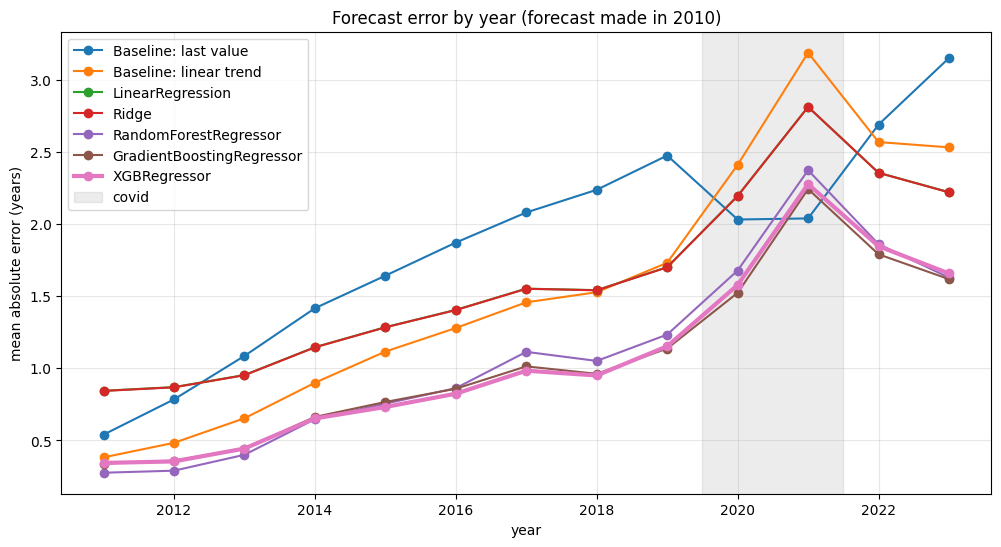

In [43]:
mae_year=pd.DataFrame()
for name, pred in test_predictions.items():
    mae_year[name]=(pred-test['le_future']).abs().groupby(test['target_year']).mean()

plt.figure(figsize=(12, 6))
for name in mae_year.columns:
    width=3 if name==best_model_name else 1.5
    plt.plot(mae_year.index, mae_year[name], marker='o', label=name, linewidth=width)
plt.axvspan(2019.5, 2021.5, color='grey', alpha=0.15, label='covid')
plt.title('Forecast error by year (forecast made in 2010)')
plt.xlabel('year')
plt.ylabel('mean absolute error (years)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 
- The error grows the further ahead we forecast: XGBoost goes from about 0.35 years in 2011 to about 1.15 in 2019
- Covid makes the error jump to about 2.3 years in 2021, then it comes down again as countries recover
- The tree models (XGBoost, gradient boosting, random forest) are the best every year. Linear regression and Ridge give the same result (the lines are on top of each other)

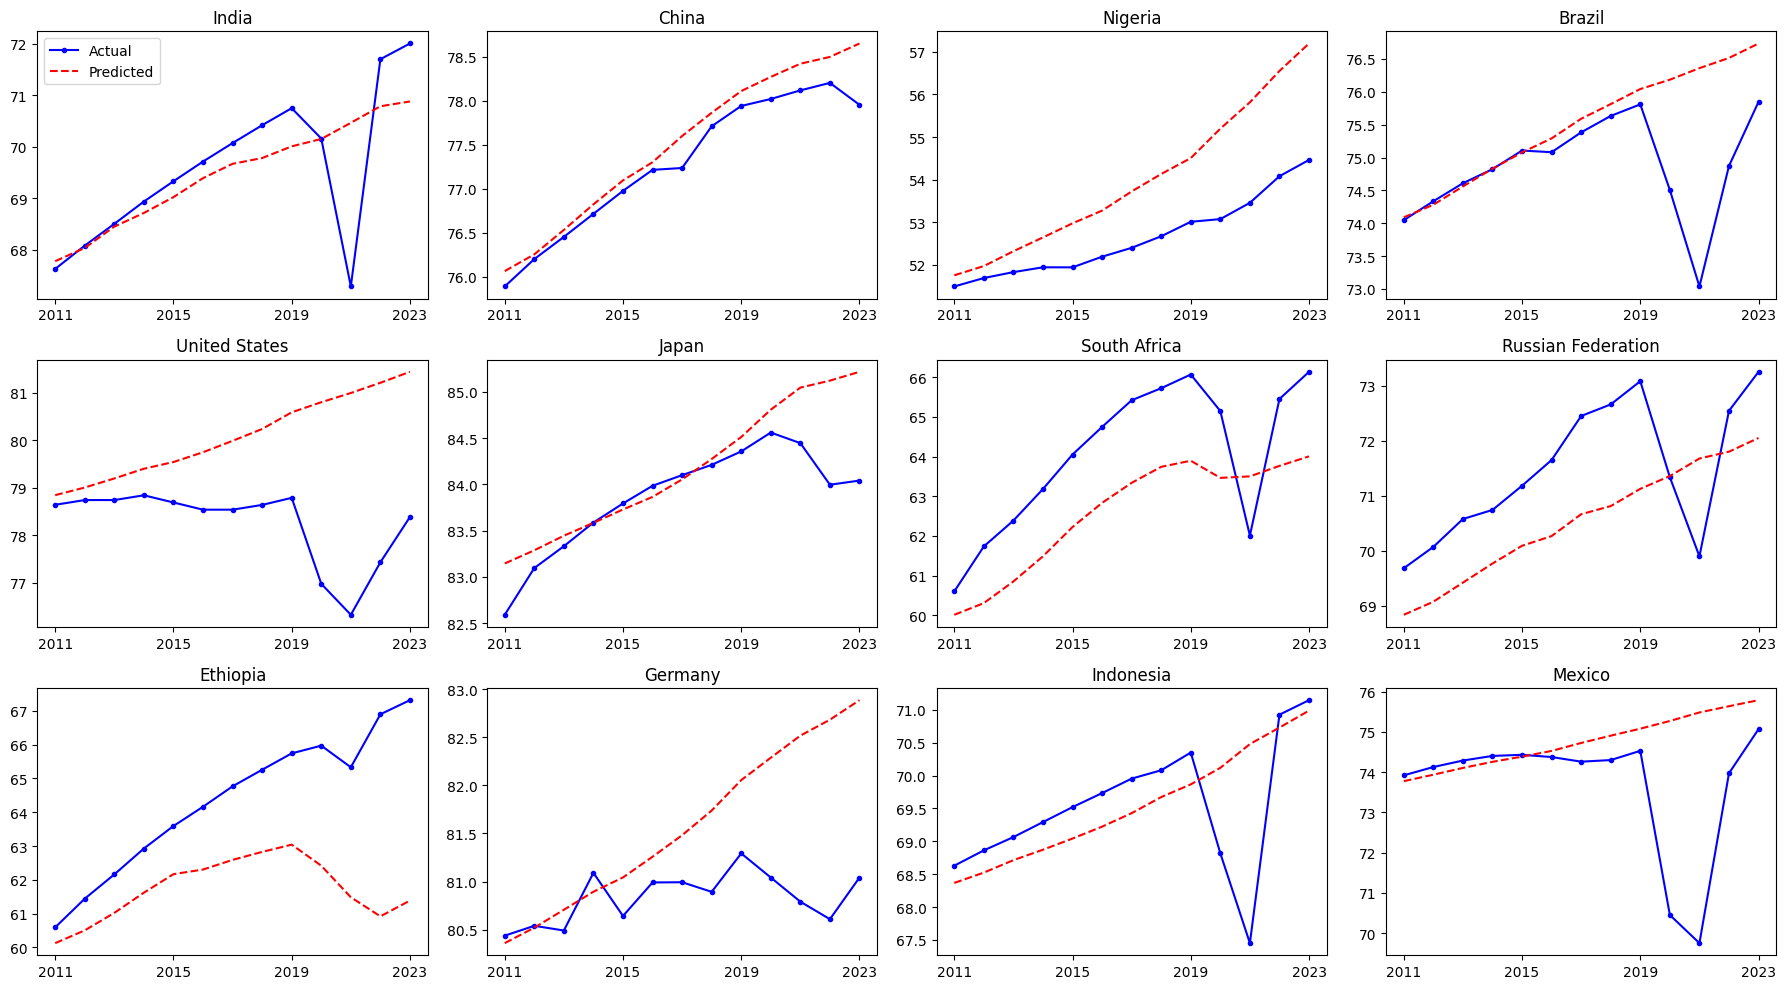

In [44]:
def plot_actual_vs_predicted(test, countries):
    plt.figure(figsize=(18, 10))
    for i, country in enumerate(countries, 1):
        temp=test[test['Country Name']==country].sort_values('target_year')
        plt.subplot(3, 4, i)
        plt.plot(temp['target_year'], temp['le_future'], color="blue", label="Actual", marker="o", markersize=3)
        plt.plot(temp['target_year'], temp['prediction'], color="red", label="Predicted", linestyle="--")
        plt.title(country)
        plt.xticks([2011, 2015, 2019, 2023])
        if i==1:
            plt.legend()
    plt.tight_layout()
    plt.show()


plot_actual_vs_predicted(test, ['India', 'China', 'Nigeria', 'Brazil', 'United States', 'Japan',
                                'South Africa', 'Russian Federation', 'Ethiopia', 'Germany', 'Indonesia', 'Mexico'])

### 
- Good forecasts until 2019 for India, China, Brazil, Japan and Indonesia. The covid drop could not be predicted from 2010 data
- Too high for the United States, Germany, Nigeria and Mexico: their life expectancy grew much slower after 2010 while the model expected the old trend to continue
- Too low for South Africa, Ethiopia and Russia: they improved faster than expected

In [45]:

test.groupby('Country Name')[['abs_error', 'error']].mean().sort_values('abs_error', ascending=False).head(10).round(2)

,abs_error,error
Country Name,,
Central African Republic,11.46,11.20
South Sudan,9.45,9.45
Syrian Arab Republic,6.00,6.00
"Somalia, Fed. Rep.",3.45,0.16
Zimbabwe,3.16,-3.16
Sao Tome and Principe,2.66,-2.66
Ethiopia,2.59,-2.59
Haiti,2.59,1.44
Uganda,2.59,-2.59


### 
The biggest errors are in countries with wars (Central African Republic, South Sudan, Syria), where life expectancy suddenly collapsed. No model trained on past data can predict these

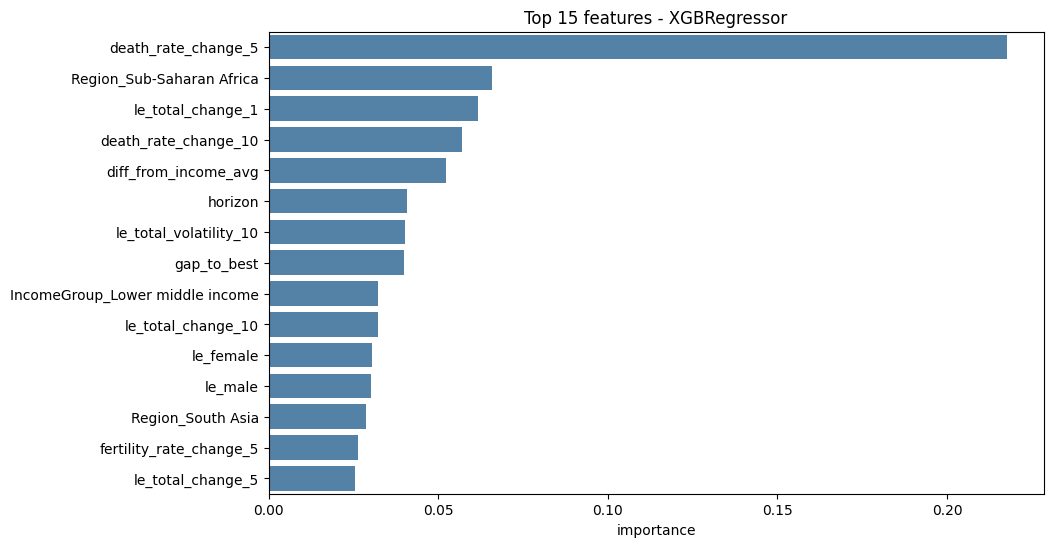

In [46]:
best_model=models[models_names.index(best_model_name)]
importance=pd.Series(best_model.feature_importances_, index=inputs).sort_values(ascending=False)
plt.figure(figsize=(10, 6))
sns.barplot(x=importance.head(15).values, y=importance.head(15).index, color='steelblue')
plt.title(f'Top 15 features - {best_model_name}')
plt.xlabel('importance')
plt.ylabel('')
plt.show()

### 
The most important feature by far is death_rate_change_5 (how fast the death rate fell in the last 5 years), then Region_Sub-Saharan Africa, le_total_change_1 (last year's change), death_rate_change_10 and diff_from_income_avg. So the recent speed of improvement is the strongest signal for the future, and Sub-Saharan African countries behave differently from the rest. The horizon is also important because the change gets bigger the further ahead we forecast

### model performance, challenges and improvements

### 
**How well the model performed**

Using only data till 2010, XGBoost forecasts life expectancy for 2011 - 2023 with an average error of about 1 year (MAE 1.06, MAPE 1.65%), and only 0.72 years before covid. The model follows countries with steady progress well, but it can not predict shocks like covid or wars, and it does not know when a trend changes.

**Challenges**
- shocks can not be predicted from past data and they cause most of the error
- Model selection uses one validation origin. Nearby training rows also share underlying history
- the trend changed between the validation and test periods: 1998 - 2010 had faster improvement than before (negative bias), 2011 - 2023 had slower improvement in rich countries like the United States and Germany plus covid (positive bias)
- only 5 indicators are available, there is no information about income, health spending or age structure

**Ideas for improvement**
- add more features available till 2010: GDP per capita, health expenditure, HIV prevalence, child mortality, vaccination, urbanization and age structure
- forecast male and female life expectancy separately and combine them
- use several validation periods (rolling origin) instead of one to choose the model and tune hyperparameters
- give prediction intervals instead of a single value and handle shocks with scenarios